# Cross-method random-label selectivity analysis

This read-only notebook combines the completed mean-difference, logistic-regression,
DAS, and MLP-1 runs for GPT-2 Small and Qwen3-0.6B Base. It does not tune or train any
probe and does not require a Hugging Face token.

The primary analysis follows the selectivity presentation from Hewitt and Liang:
each method has a real-task accuracy point and a random-label accuracy point, joined
by a vertical segment. The segment is selectivity, `real accuracy − random-label
accuracy`. Native and midpoint decision rules are kept separate.

## 1. Settings

Use the same Drive root and run ID as Notebooks 12–15. Held-out test accuracy is the
primary result. Leave `USE_BALANCED_ACCURACY_FOR_PLOTS = False` so the first plot pair
remains ordinary accuracy. A dedicated section below always produces the corresponding
balanced-accuracy tables and plots as a class-imbalance sensitivity analysis.

In [1]:
PROJECT_URL = "https://github.com/Adefioye/sentiment-manifold.git"
PROJECT_REVISION = None  # Optional immutable commit or tag.
DRIVE_ROOT = "/content/drive/MyDrive/sentiment-geometry/selectivity"
RUN_ID = "fixed-layer-selectivity-v1"
ANALYSIS_SPLIT = "test"
USE_BALANCED_ACCURACY_FOR_PLOTS = False

## 2. Install the reporting package and mount Drive

This installs the editable project checkout and verifies only the reporting APIs used
below. No model is loaded and no experiment output is overwritten.

In [2]:
import importlib
import os
import subprocess
import sys
from pathlib import Path

from google.colab import drive

PROJECT_ROOT = Path("/content/sentiment-manifold")
if not (PROJECT_ROOT / ".git").is_dir():
    subprocess.run(["git", "clone", PROJECT_URL, str(PROJECT_ROOT)], check=True)
if PROJECT_REVISION is not None:
    subprocess.run(
        ["git", "checkout", "--detach", PROJECT_REVISION],
        cwd=PROJECT_ROOT,
        check=True,
    )
project_commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True
).strip()
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-e", f"{PROJECT_ROOT}[notebooks]"],
    check=True,
)
os.chdir(PROJECT_ROOT)
root_string = str(PROJECT_ROOT.resolve())
if root_string in sys.path:
    sys.path.remove(root_string)
sys.path.insert(0, root_string)
for module_name in list(sys.modules):
    if module_name == "sentiment_geometry" or module_name.startswith(
        "sentiment_geometry."
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

reporting = importlib.import_module("sentiment_geometry.reporting")
required = {
    "build_fixed_layer_selectivity_accuracy_tables",
    "combine_fixed_layer_selectivity_runs",
    "plot_fixed_layer_selectivity_accuracy_gaps",
    "save_fixed_layer_selectivity_accuracy_tables",
    "save_fixed_layer_selectivity_balanced_accuracy_tables",
}
missing = sorted(name for name in required if not hasattr(reporting, name))
if missing:
    raise ImportError(f"sentiment_geometry.reporting is missing {missing}.")

drive.mount("/content/drive")
RUN_ROOT = Path(DRIVE_ROOT) / RUN_ID
if not RUN_ROOT.is_dir():
    raise FileNotFoundError(f"No selectivity run directory at {RUN_ROOT}")
print("Project commit:", project_commit)
print("Shared run root:", RUN_ROOT)

Mounted at /content/drive
Project commit: a699a00b83c03d9b7ecd64e5d87d6a04dd5c8e18
Shared run root: /content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1


## 3. Combine the eight completed method/model runs

Aggregation is deliberately strict: it stops if any method/model run lacks its final
metrics or selectivity summary. This prevents a partial study from looking complete.
The combined CSV files are written under the same Drive run ID in `combined/`.

In [3]:
from sentiment_geometry.reporting import combine_fixed_layer_selectivity_runs

COMBINED_DIR = combine_fixed_layer_selectivity_runs(RUN_ROOT)
print("Combined artifacts:", COMBINED_DIR)

Combined artifacts: /content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1/combined


## 4. Native-rule accuracy and selectivity table

Each row is one model/dataset/method combination on the held-out split. Means and
standard deviations are computed across paired seeds. The 95% confidence interval is
computed from the paired per-seed selectivity differences, not by subtracting two
independently aggregated intervals.

In [4]:
import pandas as pd
from IPython.display import Image, display

from sentiment_geometry.reporting import (
    build_fixed_layer_selectivity_accuracy_tables,
    plot_fixed_layer_selectivity_accuracy_gaps,
    save_fixed_layer_selectivity_accuracy_tables,
    save_fixed_layer_selectivity_balanced_accuracy_tables,
)

NATIVE_TABLE, MIDPOINT_TABLE = build_fixed_layer_selectivity_accuracy_tables(
    COMBINED_DIR,
    split=ANALYSIS_SPLIT,
)
TABLE_PATHS = save_fixed_layer_selectivity_accuracy_tables(
    COMBINED_DIR,
    split=ANALYSIS_SPLIT,
)

TABLE_COLUMNS = [
    "model",
    "dataset",
    "layer",
    "method_label",
    "accuracy_real_mean",
    "accuracy_real_std",
    "accuracy_random_mean",
    "accuracy_random_std",
    "accuracy_selectivity_mean",
    "accuracy_selectivity_ci95_low",
    "accuracy_selectivity_ci95_high",
    "balanced_accuracy_real_mean",
    "balanced_accuracy_random_mean",
    "balanced_accuracy_selectivity_mean",
    "accuracy_n_seeds",
]
print("Native-rule table saved to:", TABLE_PATHS[0])
display(NATIVE_TABLE[TABLE_COLUMNS].round(4))

Native-rule table saved to: /content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1/combined/analysis/native_test_accuracy_selectivity.csv


,model,dataset,layer,method_label,accuracy_real_mean,accuracy_real_std,accuracy_random_mean,accuracy_random_std,accuracy_selectivity_mean,accuracy_selectivity_ci95_low,accuracy_selectivity_ci95_high,balanced_accuracy_real_mean,balanced_accuracy_random_mean,balanced_accuracy_selectivity_mean,accuracy_n_seeds
0,gpt2-small,full_ait,11,Mean difference,0.7637,0.0000,0.5073,0.0154,0.2564,0.2429,0.2699,0.7637,0.5073,0.2564,5
1,gpt2-small,full_ait,11,Logistic regression,0.8626,0.0000,0.4963,0.0361,0.3663,0.3346,0.3980,0.8626,0.4963,0.3663,5
2,gpt2-small,full_ait,11,DAS,0.6377,0.0074,0.4813,0.0115,0.1564,0.1490,0.1638,0.6377,0.4813,0.1564,5
3,gpt2-small,full_ait,11,MLP-1,0.8670,0.0057,0.4919,0.0163,0.3751,0.3588,0.3914,0.8670,0.4919,0.3751,5
4,gpt2-small,toy_movie_review,10,Mean difference,1.0000,0.0000,0.5333,0.1179,0.4667,0.3634,0.5700,1.0000,0.5277,0.4723,5
5,gpt2-small,toy_movie_review,10,Logistic regression,1.0000,0.0000,0.5067,0.0365,0.4933,0.4613,0.5253,1.0000,0.4991,0.5009,5
6,gpt2-small,toy_movie_review,10,DAS,0.7786,0.0160,0.5071,0.0639,0.2714,0.2240,0.3189,0.7786,0.5071,0.2714,5
7,gpt2-small,toy_movie_review,10,MLP-1,0.7867,0.2921,0.5267,0.0596,0.2600,0.0509,0.4691,0.8000,0.5429,0.2571,5
8,qwen-0.6b,full_ait,26,Mean difference,0.9142,0.0000,0.4993,0.0103,0.4150,0.4059,0.4240,0.9142,0.4993,0.4150,5
9,qwen-0.6b,full_ait,26,Logistic regression,0.8832,0.0000,0.4894,0.0215,0.3938,0.3750,0.4126,0.8832,0.4894,0.3938,5


## 5. Midpoint-rule accuracy and selectivity table

This table has the same rows and uncertainty summaries as the native table, but every
prediction uses the training-class midpoint threshold.

In [5]:
print("Midpoint-rule table saved to:", TABLE_PATHS[1])
display(MIDPOINT_TABLE[TABLE_COLUMNS].round(4))

Midpoint-rule table saved to: /content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1/combined/analysis/midpoint_test_accuracy_selectivity.csv


,model,dataset,layer,method_label,accuracy_real_mean,accuracy_real_std,accuracy_random_mean,accuracy_random_std,accuracy_selectivity_mean,accuracy_selectivity_ci95_low,accuracy_selectivity_ci95_high,balanced_accuracy_real_mean,balanced_accuracy_random_mean,balanced_accuracy_selectivity_mean,accuracy_n_seeds
0,gpt2-small,full_ait,11,Mean difference,0.7637,0.0000,0.5073,0.0154,0.2564,0.2429,0.2699,0.7637,0.5073,0.2564,5
1,gpt2-small,full_ait,11,Logistic regression,0.8681,0.0000,0.4971,0.0358,0.3711,0.3397,0.4024,0.8681,0.4971,0.3711,5
2,gpt2-small,full_ait,11,DAS,0.7930,0.0065,0.4971,0.0157,0.2960,0.2821,0.3099,0.7930,0.4971,0.2960,5
3,gpt2-small,full_ait,11,MLP-1,0.8670,0.0066,0.4993,0.0151,0.3678,0.3537,0.3818,0.8670,0.4993,0.3678,5
4,gpt2-small,toy_movie_review,10,Mean difference,1.0000,0.0000,0.5333,0.1179,0.4667,0.3634,0.5700,1.0000,0.5277,0.4723,5
5,gpt2-small,toy_movie_review,10,Logistic regression,1.0000,0.0000,0.5267,0.0365,0.4733,0.4413,0.5053,1.0000,0.5214,0.4786,5
6,gpt2-small,toy_movie_review,10,DAS,1.0000,0.0000,0.5200,0.0380,0.4800,0.4467,0.5133,1.0000,0.5179,0.4821,5
7,gpt2-small,toy_movie_review,10,MLP-1,0.9600,0.0365,0.5667,0.0408,0.3933,0.3453,0.4413,0.9571,0.5589,0.3982,5
8,qwen-0.6b,full_ait,26,Mean difference,0.9142,0.0000,0.4993,0.0103,0.4150,0.4059,0.4240,0.9142,0.4993,0.4150,5
9,qwen-0.6b,full_ait,26,Logistic regression,0.8850,0.0000,0.4887,0.0209,0.3964,0.3781,0.4146,0.8850,0.4887,0.3964,5


## 6. Hewitt-style native and midpoint plots

Blue circles are real-task means, orange squares are random-label means, and each
vertical connector is the paired selectivity gap. Error bars show standard deviation
across seeds. The dotted line is binary chance accuracy. One figure is saved for each
decision rule.

/content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1/combined/analysis/figures/hewitt_native_test_accuracy.png


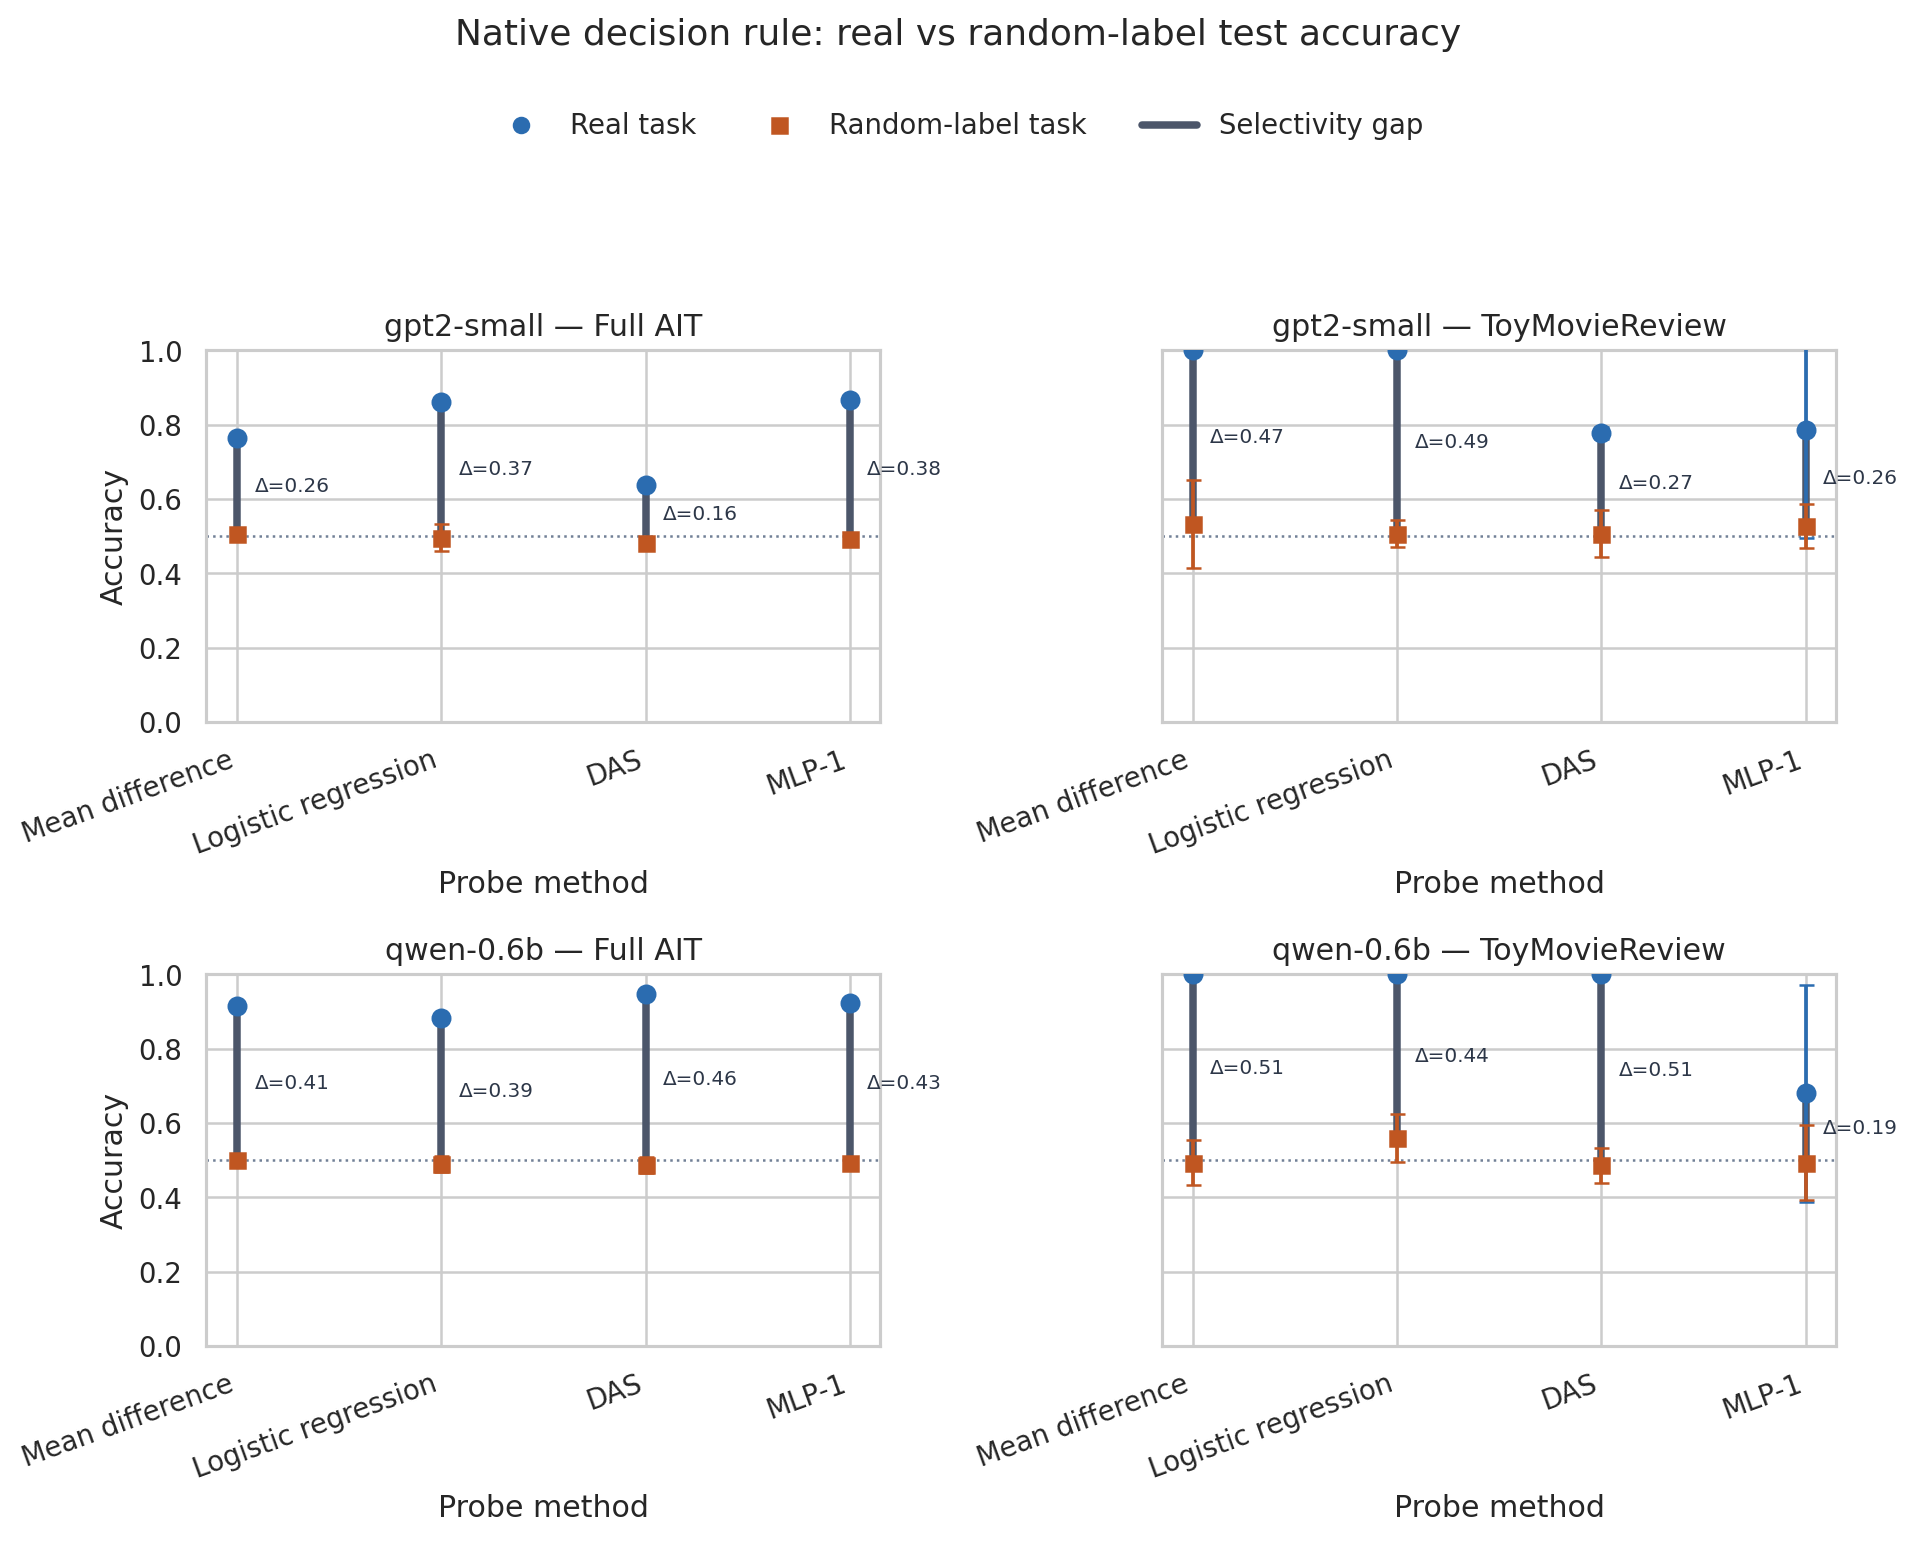

/content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1/combined/analysis/figures/hewitt_midpoint_test_accuracy.png


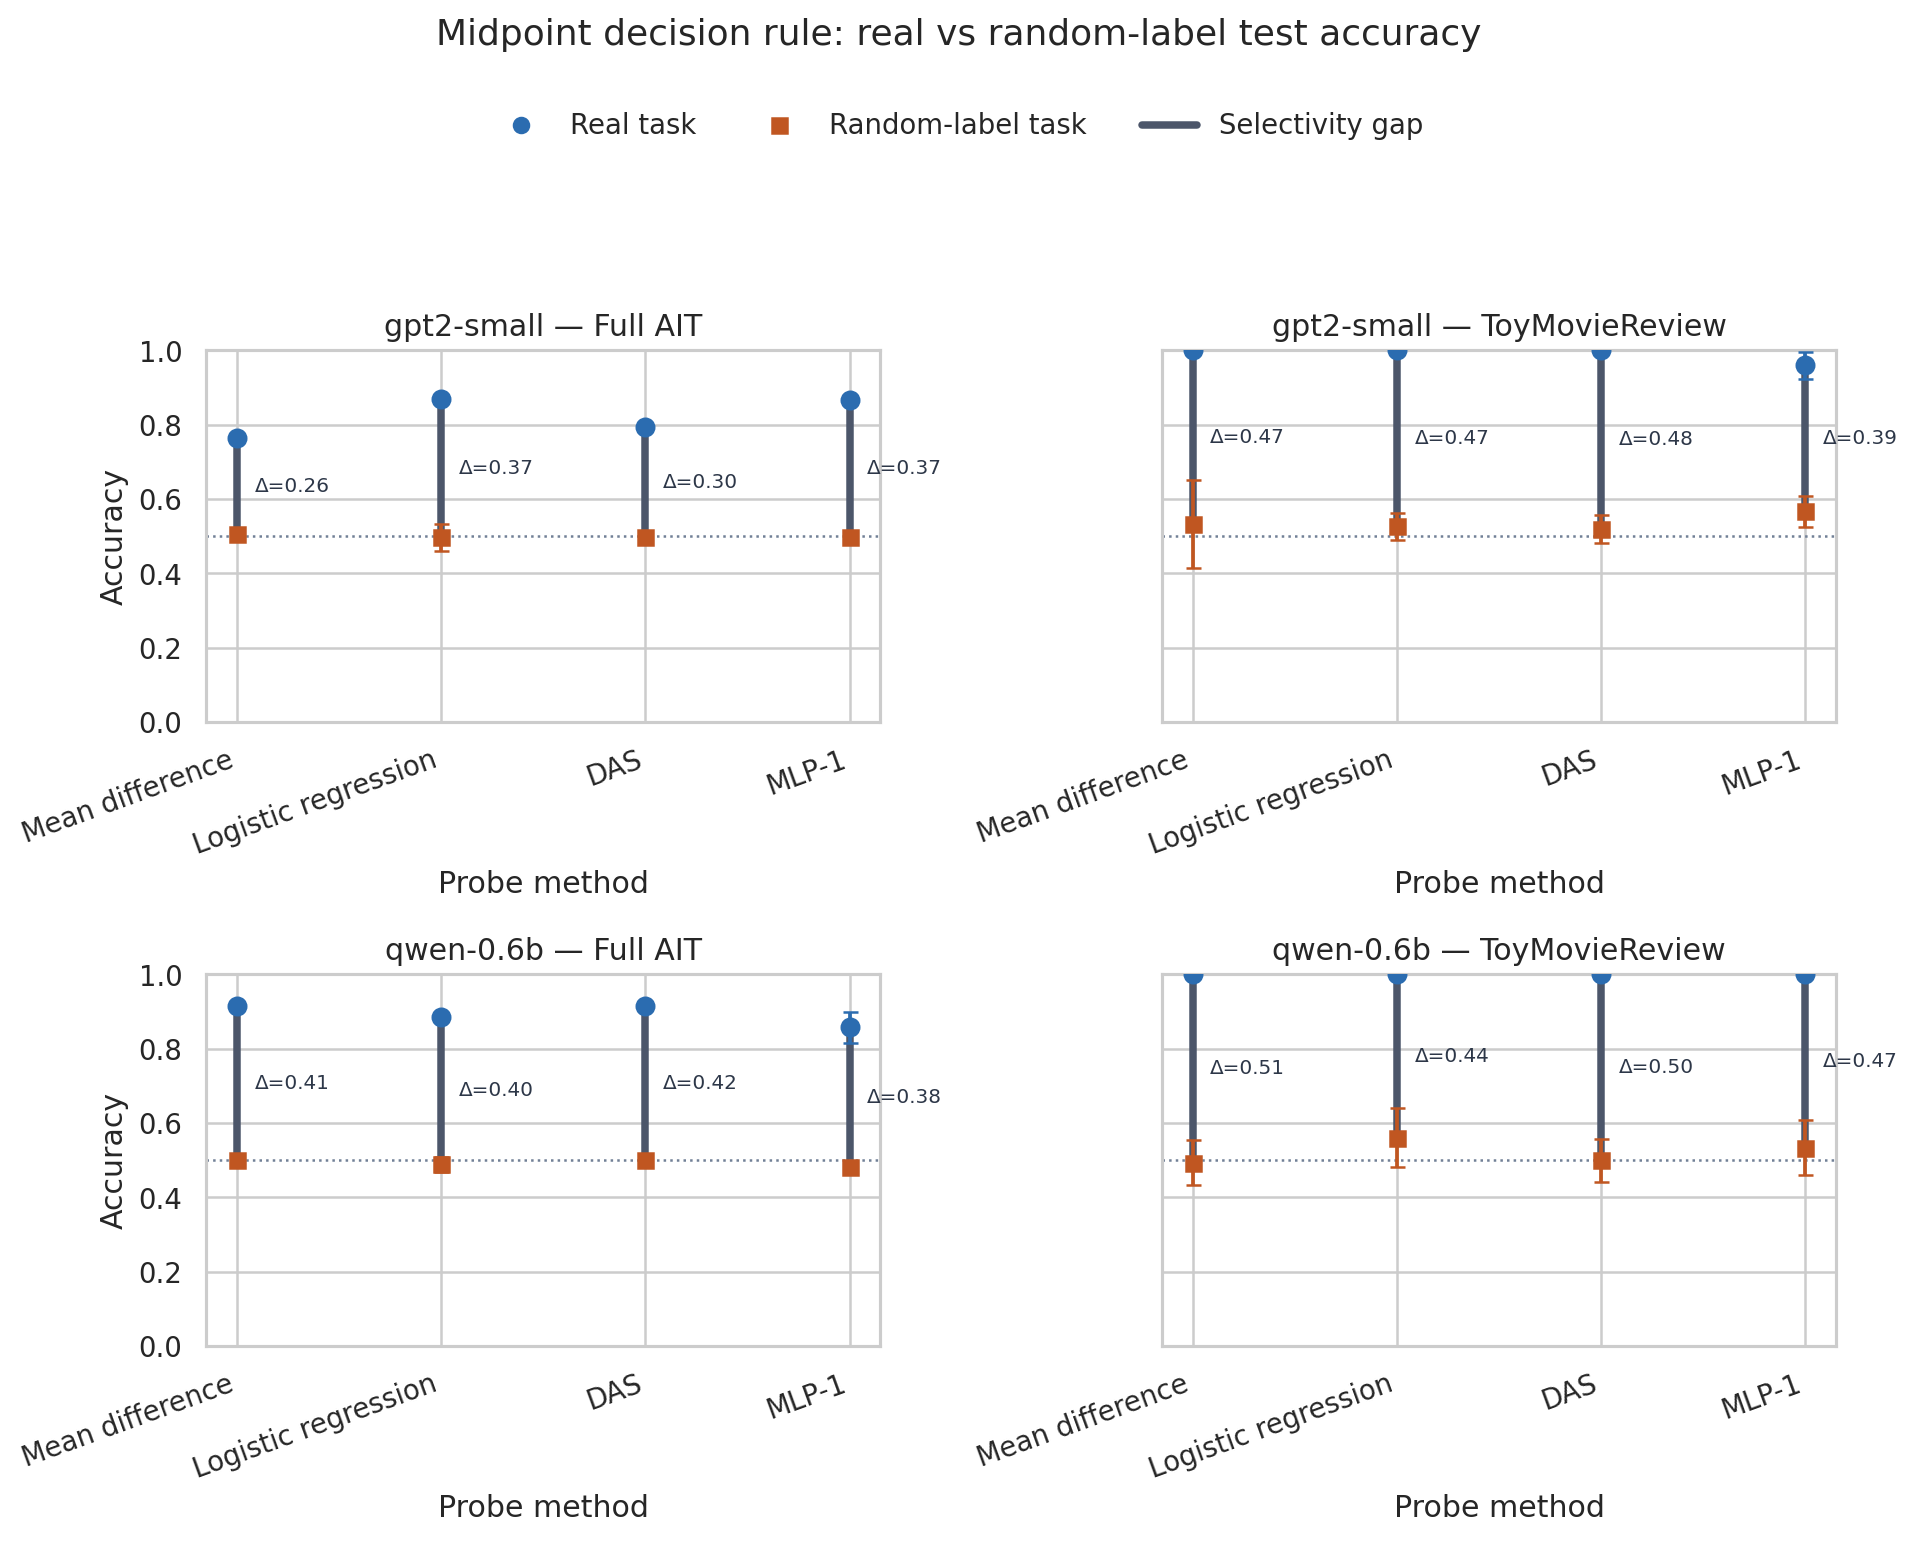

In [6]:
FIGURE_PATHS = plot_fixed_layer_selectivity_accuracy_gaps(
    COMBINED_DIR,
    split=ANALYSIS_SPLIT,
    use_balanced_accuracy=USE_BALANCED_ACCURACY_FOR_PLOTS,
)
for figure_path in FIGURE_PATHS:
    print(figure_path)
    display(Image(filename=str(figure_path)))

## 7. Native-rule balanced-accuracy and selectivity table

This is the class-balanced counterpart of the native-rule table. Positive and negative
recall receive equal weight. It is displayed separately and saved as its own CSV.

In [7]:
BALANCED_TABLE_PATHS = save_fixed_layer_selectivity_balanced_accuracy_tables(
    COMBINED_DIR,
    split=ANALYSIS_SPLIT,
)
BALANCED_TABLE_COLUMNS = [
    "model",
    "dataset",
    "layer",
    "method_label",
    "balanced_accuracy_real_mean",
    "balanced_accuracy_real_std",
    "balanced_accuracy_random_mean",
    "balanced_accuracy_random_std",
    "balanced_accuracy_selectivity_mean",
    "balanced_accuracy_selectivity_ci95_low",
    "balanced_accuracy_selectivity_ci95_high",
    "balanced_accuracy_n_seeds",
]
print("Native-rule balanced-accuracy table saved to:", BALANCED_TABLE_PATHS[0])
display(NATIVE_TABLE[BALANCED_TABLE_COLUMNS].round(4))

Native-rule balanced-accuracy table saved to: /content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1/combined/analysis/native_test_balanced_accuracy_selectivity.csv


,model,dataset,layer,method_label,balanced_accuracy_real_mean,balanced_accuracy_real_std,balanced_accuracy_random_mean,balanced_accuracy_random_std,balanced_accuracy_selectivity_mean,balanced_accuracy_selectivity_ci95_low,balanced_accuracy_selectivity_ci95_high,balanced_accuracy_n_seeds
0,gpt2-small,full_ait,11,Mean difference,0.7637,0.0000,0.5073,0.0154,0.2564,0.2429,0.2699,5
1,gpt2-small,full_ait,11,Logistic regression,0.8626,0.0000,0.4963,0.0361,0.3663,0.3346,0.3980,5
2,gpt2-small,full_ait,11,DAS,0.6377,0.0074,0.4813,0.0115,0.1564,0.1490,0.1638,5
3,gpt2-small,full_ait,11,MLP-1,0.8670,0.0057,0.4919,0.0163,0.3751,0.3588,0.3914,5
4,gpt2-small,toy_movie_review,10,Mean difference,1.0000,0.0000,0.5277,0.1169,0.4723,0.3698,0.5748,5
5,gpt2-small,toy_movie_review,10,Logistic regression,1.0000,0.0000,0.4991,0.0444,0.5009,0.4620,0.5398,5
6,gpt2-small,toy_movie_review,10,DAS,0.7786,0.0160,0.5071,0.0639,0.2714,0.2240,0.3189,5
7,gpt2-small,toy_movie_review,10,MLP-1,0.8000,0.2739,0.5429,0.0407,0.2571,0.0511,0.4631,5
8,qwen-0.6b,full_ait,26,Mean difference,0.9142,0.0000,0.4993,0.0103,0.4150,0.4059,0.4240,5
9,qwen-0.6b,full_ait,26,Logistic regression,0.8832,0.0000,0.4894,0.0215,0.3938,0.3750,0.4126,5


## 8. Midpoint-rule balanced-accuracy and selectivity table

This applies the training-class midpoint threshold and then gives the positive and
negative classes equal weight in the reported accuracy.

In [8]:
print("Midpoint-rule balanced-accuracy table saved to:", BALANCED_TABLE_PATHS[1])
display(MIDPOINT_TABLE[BALANCED_TABLE_COLUMNS].round(4))

Midpoint-rule balanced-accuracy table saved to: /content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1/combined/analysis/midpoint_test_balanced_accuracy_selectivity.csv


,model,dataset,layer,method_label,balanced_accuracy_real_mean,balanced_accuracy_real_std,balanced_accuracy_random_mean,balanced_accuracy_random_std,balanced_accuracy_selectivity_mean,balanced_accuracy_selectivity_ci95_low,balanced_accuracy_selectivity_ci95_high,balanced_accuracy_n_seeds
0,gpt2-small,full_ait,11,Mean difference,0.7637,0.0000,0.5073,0.0154,0.2564,0.2429,0.2699,5
1,gpt2-small,full_ait,11,Logistic regression,0.8681,0.0000,0.4971,0.0358,0.3711,0.3397,0.4024,5
2,gpt2-small,full_ait,11,DAS,0.7930,0.0065,0.4971,0.0157,0.2960,0.2821,0.3099,5
3,gpt2-small,full_ait,11,MLP-1,0.8670,0.0066,0.4993,0.0151,0.3678,0.3537,0.3818,5
4,gpt2-small,toy_movie_review,10,Mean difference,1.0000,0.0000,0.5277,0.1169,0.4723,0.3698,0.5748,5
5,gpt2-small,toy_movie_review,10,Logistic regression,1.0000,0.0000,0.5214,0.0439,0.4786,0.4401,0.5171,5
6,gpt2-small,toy_movie_review,10,DAS,1.0000,0.0000,0.5179,0.0372,0.4821,0.4495,0.5148,5
7,gpt2-small,toy_movie_review,10,MLP-1,0.9571,0.0391,0.5589,0.0477,0.3982,0.3484,0.4481,5
8,qwen-0.6b,full_ait,26,Mean difference,0.9142,0.0000,0.4993,0.0103,0.4150,0.4059,0.4240,5
9,qwen-0.6b,full_ait,26,Logistic regression,0.8850,0.0000,0.4887,0.0209,0.3964,0.3781,0.4146,5


## 9. Hewitt-style native and midpoint balanced-accuracy plots

These two additional plots use balanced accuracy on the y-axis. They are displayed
below the ordinary-accuracy plots and saved under distinct filenames, so neither plot
pair overwrites the other.

/content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1/combined/analysis/figures/hewitt_native_test_balanced_accuracy.png


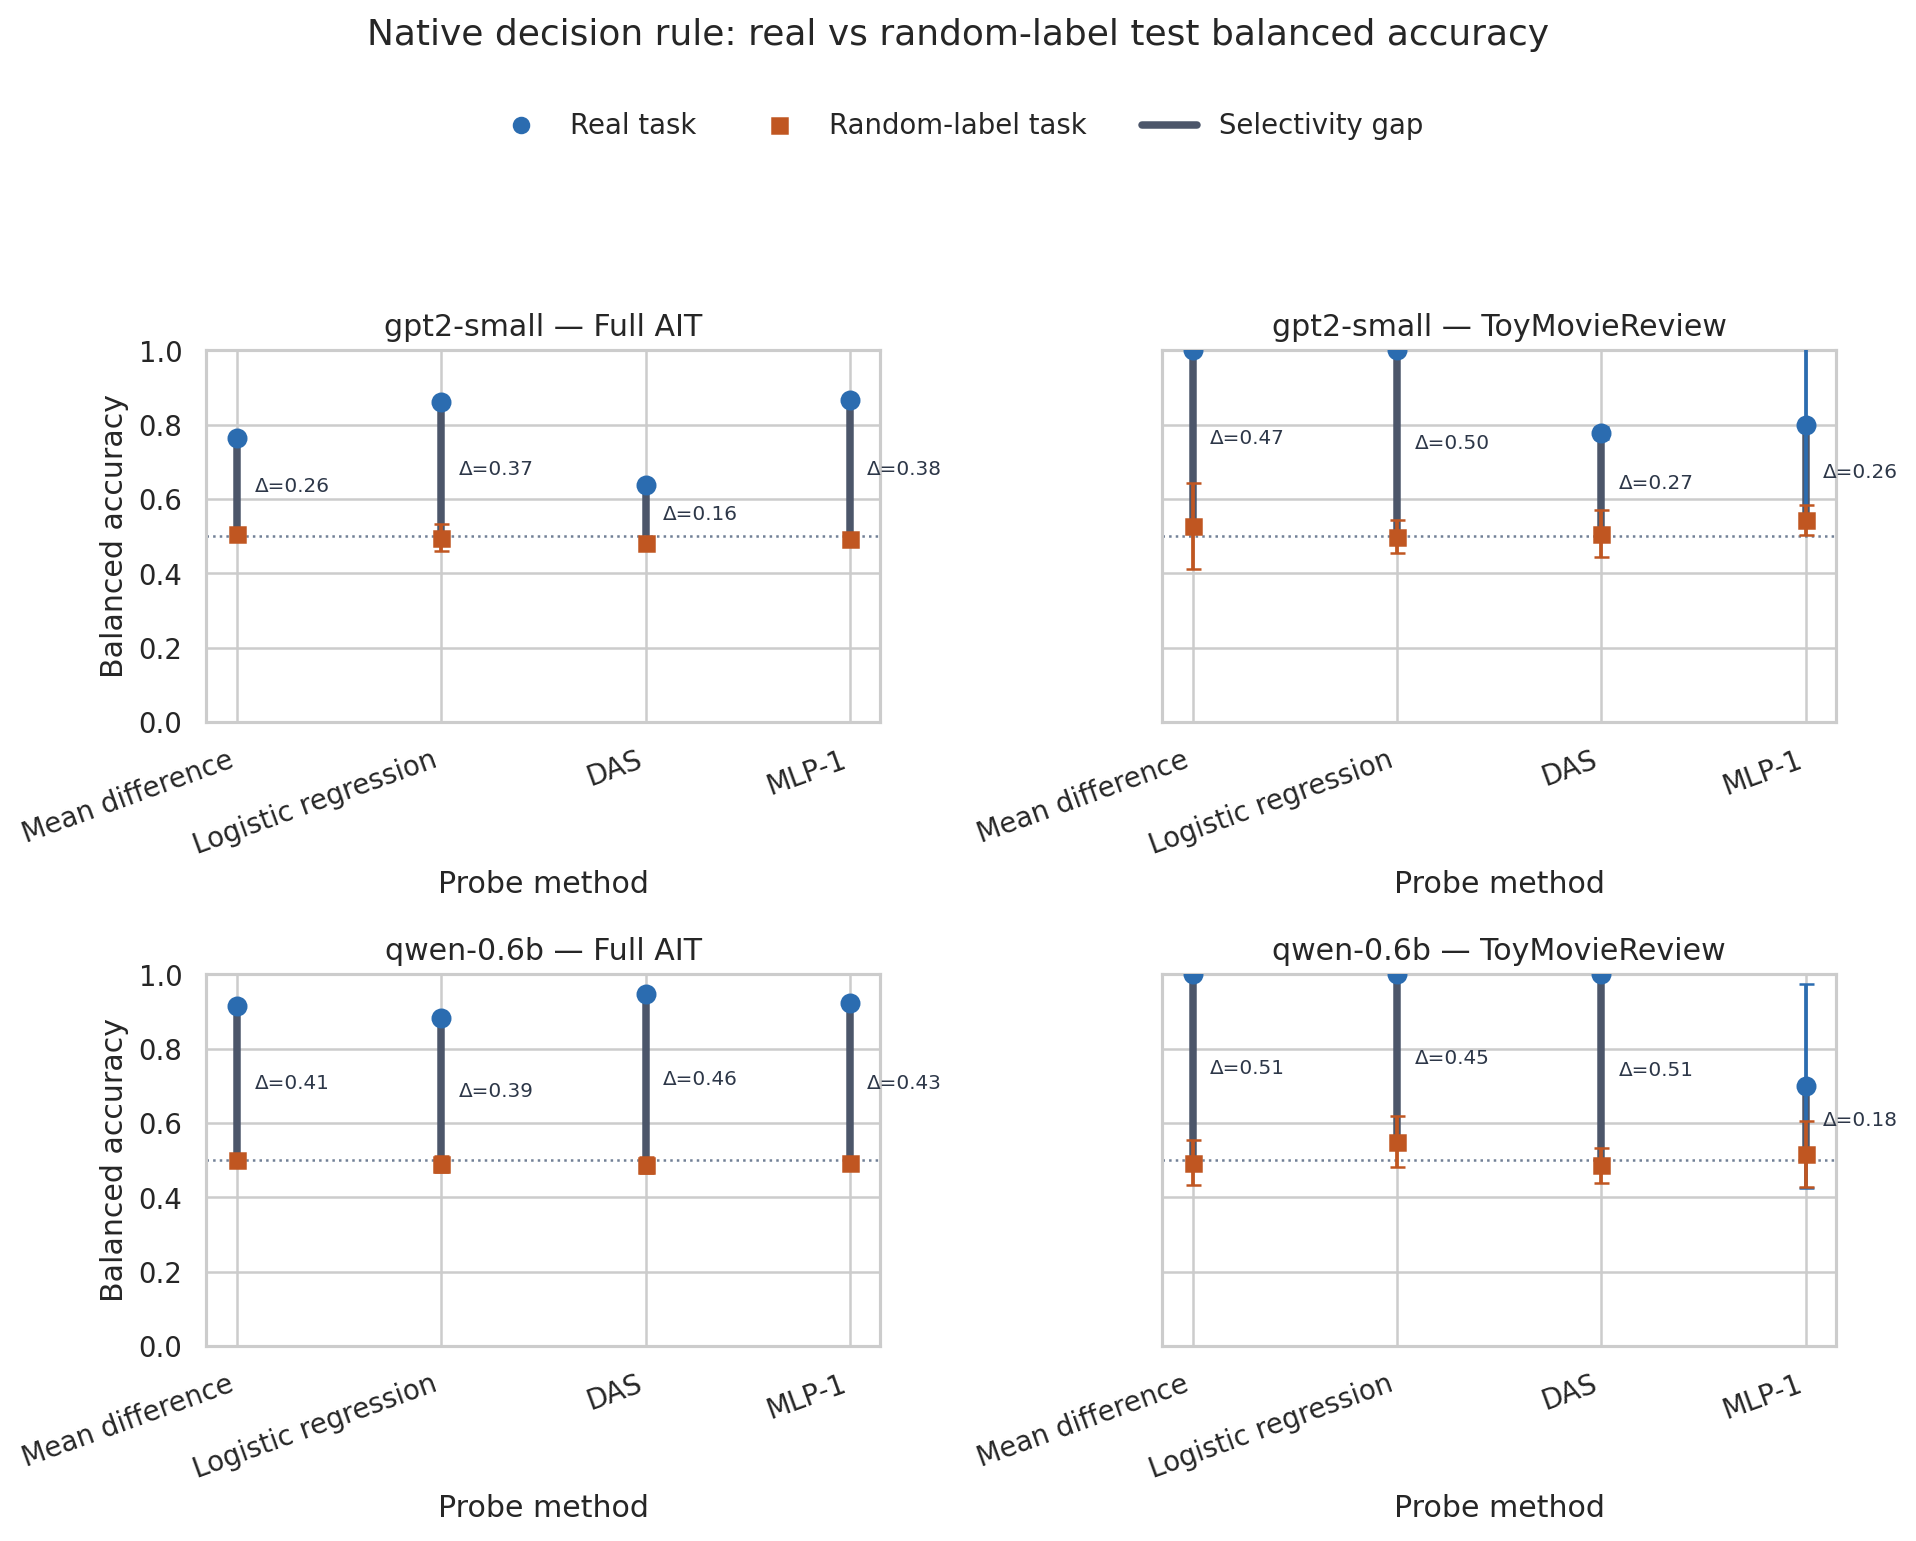

/content/drive/MyDrive/sentiment-geometry/selectivity/fixed-layer-selectivity-v1/combined/analysis/figures/hewitt_midpoint_test_balanced_accuracy.png


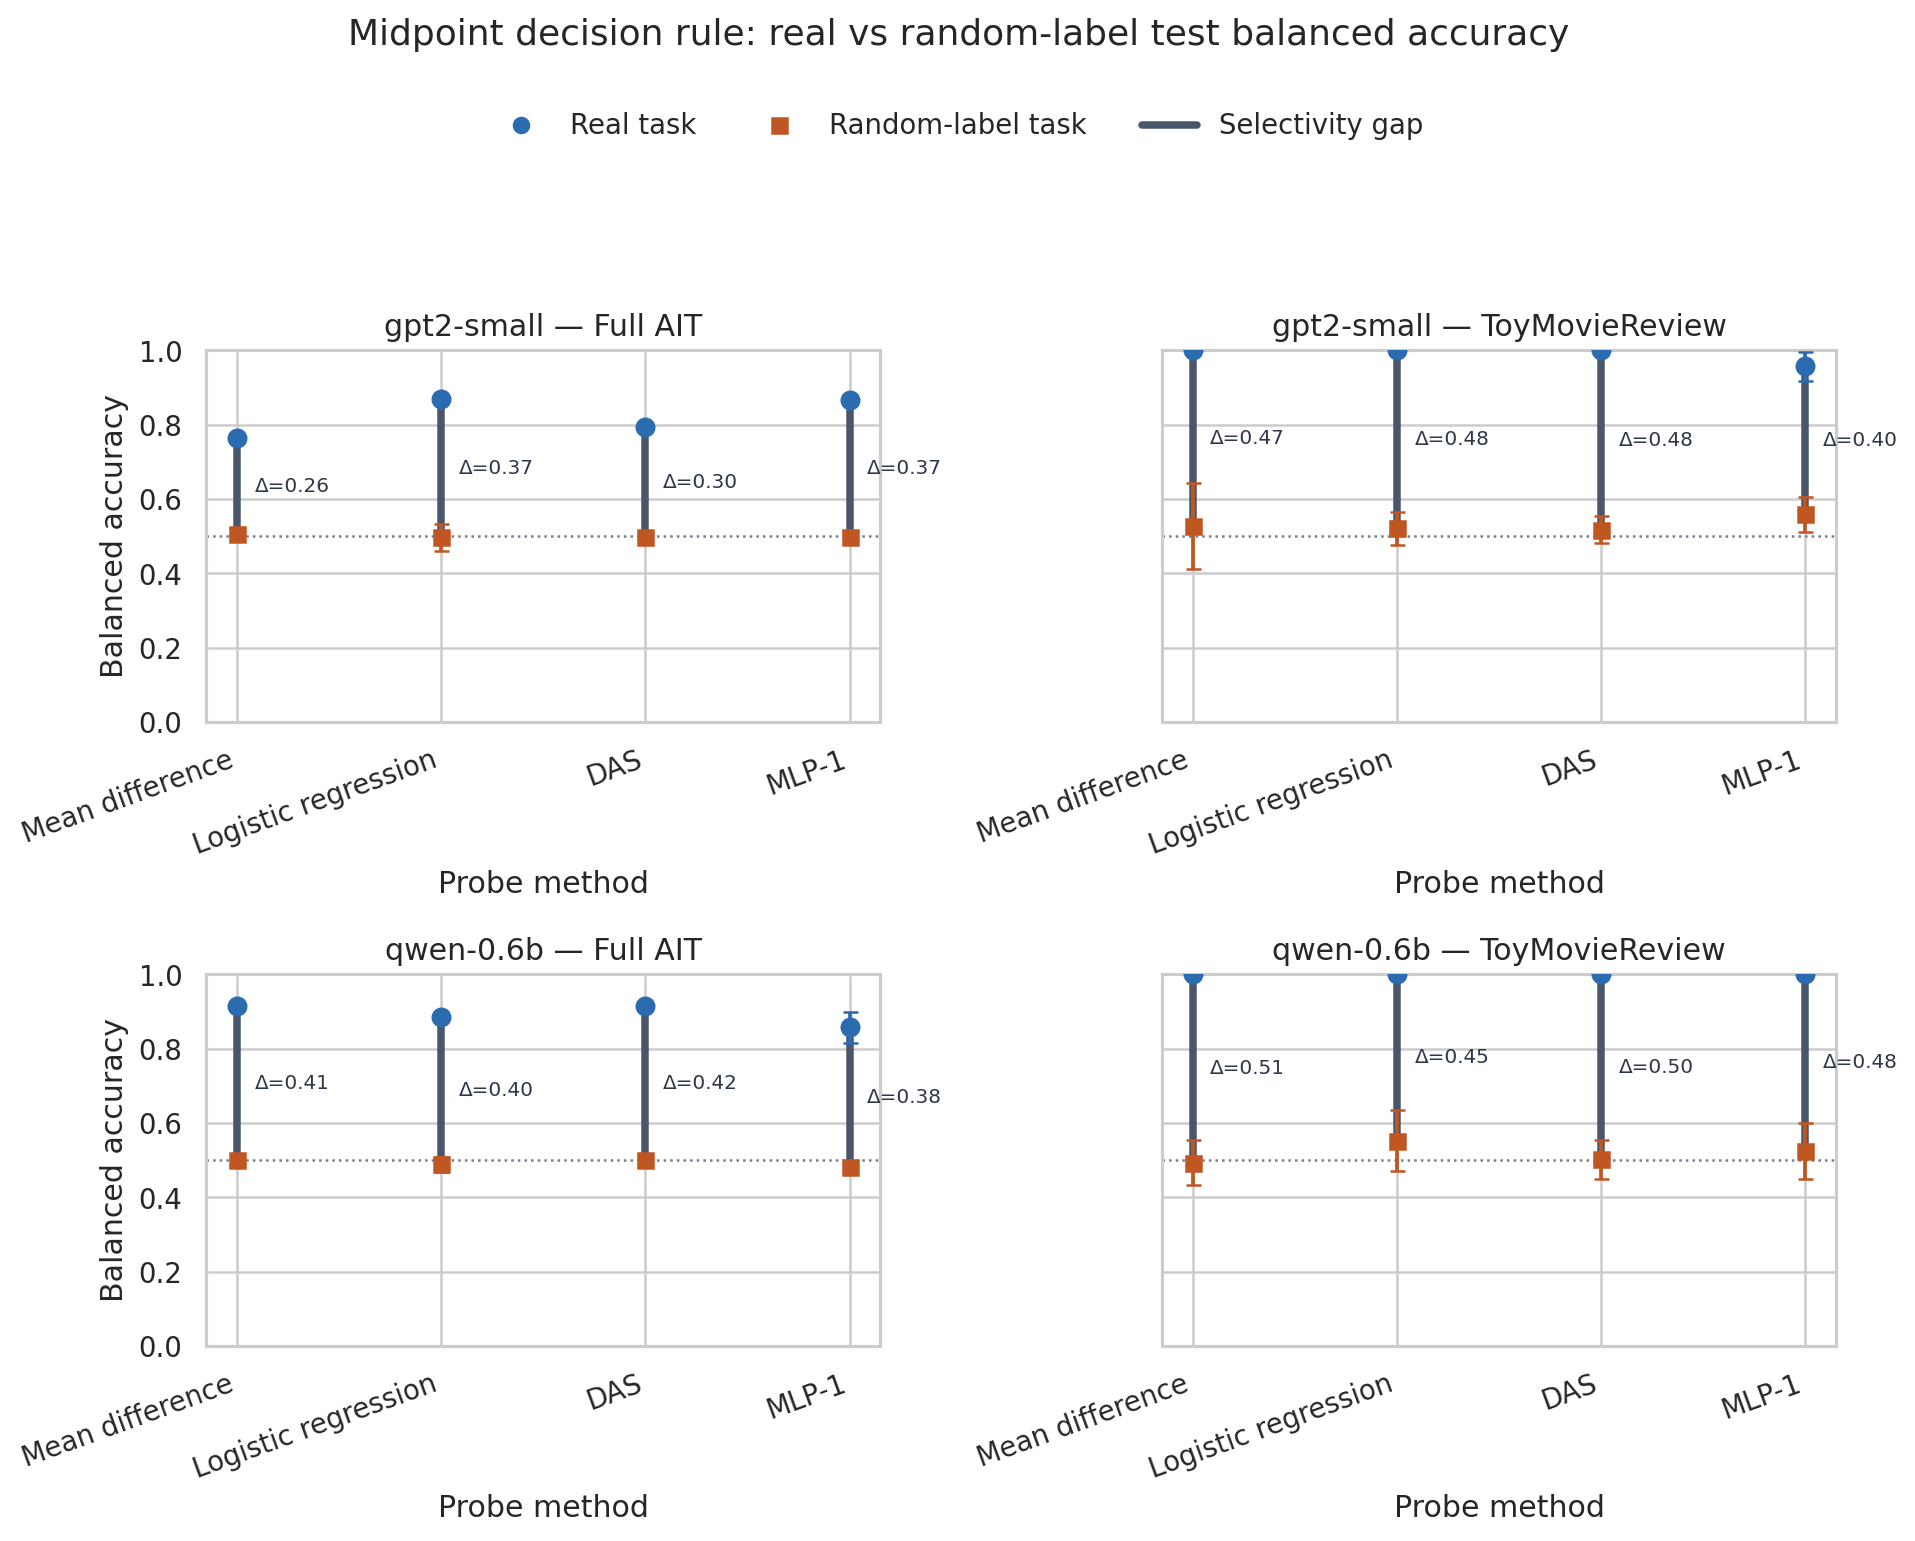

In [9]:
BALANCED_FIGURE_PATHS = plot_fixed_layer_selectivity_accuracy_gaps(
    COMBINED_DIR,
    split=ANALYSIS_SPLIT,
    use_balanced_accuracy=True,
)
for figure_path in BALANCED_FIGURE_PATHS:
    print(figure_path)
    display(Image(filename=str(figure_path)))

## 10. Interpretation checklist

- Treat held-out test accuracy and selectivity as the primary comparison.
- Confirm in Notebooks 12–15 that random-label training accuracy is high enough to
  demonstrate probe capacity; low control training accuracy can indicate failed
  optimization rather than strong selectivity.
- Check uncertainty across paired seeds rather than ranking methods from point
  estimates alone.
- Use the native-versus-midpoint agreement diagnostics in Notebooks 12–15 to identify
  conclusions that depend on the decision threshold.
- Keep DAS IIA, recovery, logit flip, and sign flip as separate causal evidence. They
  should not be merged into the probe-accuracy selectivity ranking.